In [19]:
import pandas as pd
df = pd.read_csv("diamonds.csv")
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
49995,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
49996,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
49997,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
49998,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df.shape
df.info()
df.describe()
df.columns

In [21]:
df.isnull().sum()
df.duplicated().sum()
# df.dtypes
# df.select_dtypes(include="object").columns


np.int64(126)

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols].hist(bins=30)
plt.tight_layout()
plt.show()

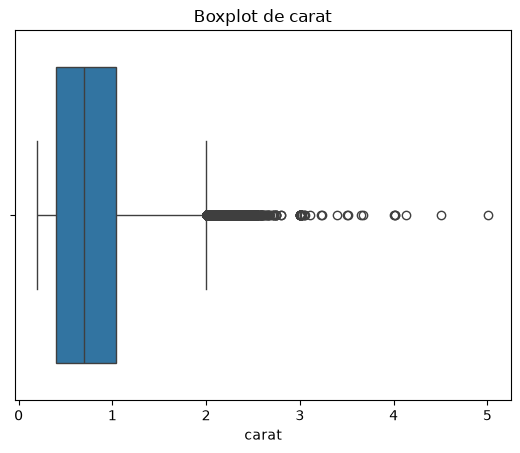

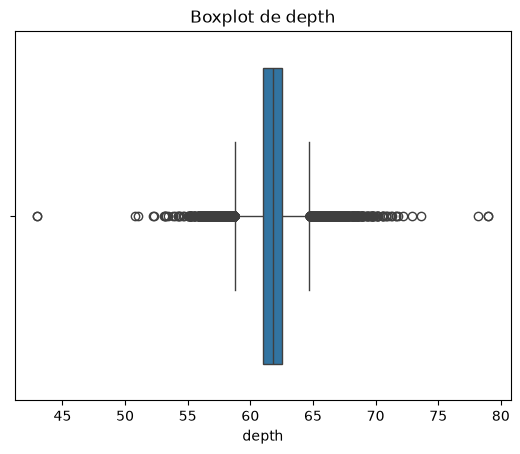

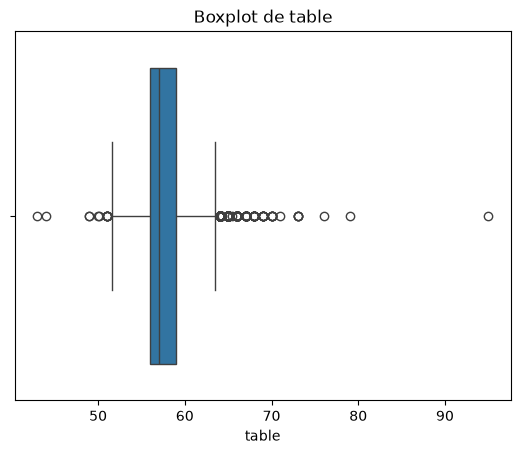

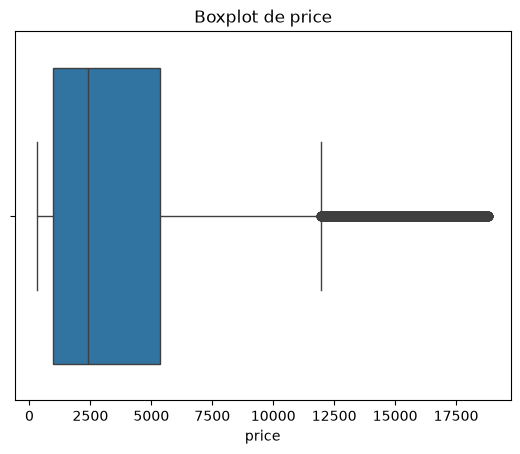

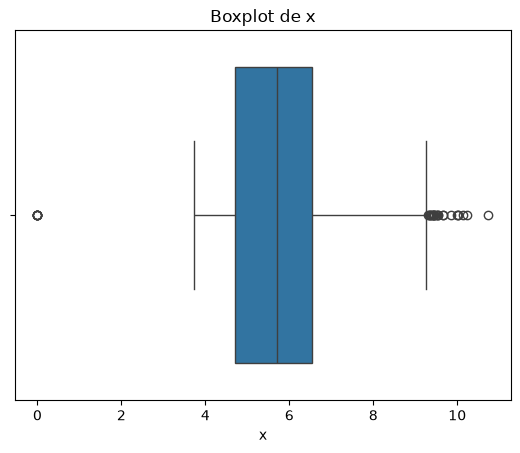

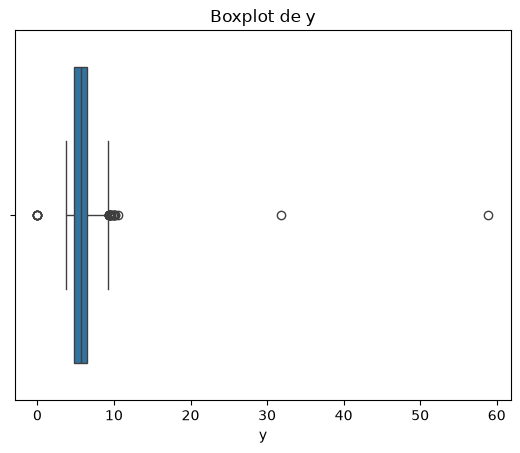

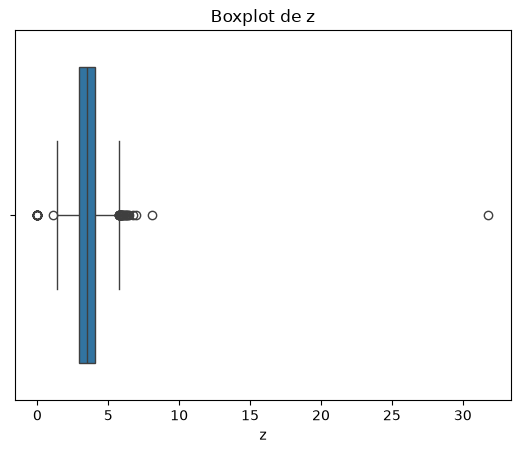

In [23]:
for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

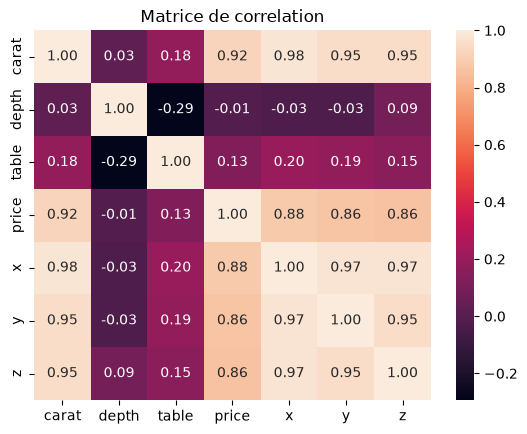

In [24]:
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f"
)
plt.title("Matrice de correlation")
plt.show()

In [17]:
numeric_cols = df.select_dtypes(include="number").columns
outlier_results = []
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Variable": col,
        "Borne inferieure": lower,
        "Borne superieure": upper,
        "Nombre d'outliers": count,
    })
outlier_df = pd.DataFrame(outlier_results)
outlier_df

,Variable,Borne inferieure,Borne superieure,Nombre d'outliers
0,carat,-0.560,2.000,1770
1,depth,58.750,64.750,2359
2,table,51.500,63.500,558
3,price,-5649.000,11951.000,3264
4,x,1.965,9.285,31
5,y,1.990,9.270,28
6,z,1.215,5.735,45


In [ ]:
dimensions = ["x", "y", "z"]
print("Dimensions ou negatives :", (df[dimensions] <= 0).sum())
print("Prix nul ou negatif :", (df["price"] <= 0).sum())
print("Carat nul ou negatif :", (df["carat"] <= 0).sum())
df.duplicated().sum()


Dimensions ou negatives : x     7
y     6
z    17
dtype: int64
Prix nul ou negatif : 0
Carat nul ou negatif : 0


np.int64(126)

In [ ]:
df = df.dropna(subset=["price"])
df = df[df["price"] > 0]
df = df[df["carat"] > 0]

df = df[(df[dimensions] > 0).all(axis=1)]
df = df.reset_index(drop=True)

df.isna().sum()

In [28]:
target = "price"
features = ["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]
X = df[features]
y = df[target]
X

,carat,cut,color,clarity,depth,table,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...
49995,0.72,Ideal,D,SI1,60.8,57.0,5.75,5.76,3.50
49996,0.72,Good,D,SI1,63.1,55.0,5.69,5.75,3.61
49997,0.70,Very Good,D,SI1,62.8,60.0,5.66,5.68,3.56
49998,0.86,Premium,H,SI2,61.0,58.0,6.15,6.12,3.74


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=25
)

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

numeric_vars = ["carat", "depth", "table", "x", "y", "z"]
ordinal_vars = ["cut", "color", "clarity"]

ordinal_categories = [
    ["Fair", "Good", "Very Good", "Premium", "Ideal"],
    ["D", "E", "F", "G", "H", "I", "J"],
    ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
]
numeric_preprocessor_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_preprocessor_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("encoder", OneHotEncoder(
    handle_unknown="ignore",
))
])

ordinal_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

preprocessor_lr = ColumnTransformer([
    ("numeric", numeric_preprocessor_lr, numeric_vars),
    ("ordinal", ordinal_preprocessor, ordinal_vars)
])

preprocessor_rf = ColumnTransformer([
    ("numeric", numeric_preprocessor_rf, numeric_vars),
    ("ordinal", ordinal_preprocessor, ordinal_vars)
])

In [ ]:
pipeline_lr = Pipeline([
    ("preprocessing", preprocessor_lr),
    ("model", LinearRegression())
])

pipeline_rf = Pipeline([
    ("preprocessing", preprocessor_rf),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_lr = cross_validate(
    pipeline_lr,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_rf = cross_validate(
    pipeline_rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_results = pd.DataFrame({
    "Modele": ["LinearRegression", "RandomForestRegressor"],
    "MAE moyen": [
        -cv_lr["test_MAE"].mean(),
        -cv_rf["test_MAE"].mean()
    ],
    "RMSE moyen": [
        -cv_lr["test_RMSE"].mean(),
        -cv_rf["test_RMSE"].mean()
    ],
    "Écart-type RMSE": [
        cv_lr["test_RMSE"].std(),
        cv_rf["test_RMSE"].std()
    ],
    "R² moyen": [
        cv_lr["test_R2"].mean(),
        cv_rf["test_R2"].mean()
    ]
})

display(cv_results.round(3))

In [ ]:
param_grid_lr = {
    "model__fit_intercept": [True, False]
}

param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_leaf": [1, 2]
}

In [ ]:
grid_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_lr.fit(X_train, y_train)
grid_rf.fit(X_train, y_train)

In [ ]:
print("LINEAR REGRESSION")
print("Meilleurs parametres :", grid_lr.best_params_)
print("Meilleur RMSE CV :", -grid_lr.best_score_)

print("\nRANDOM FOREST")
print("Meilleurs parametres :", grid_rf.best_params_)
print("Meilleur RMSE CV :", -grid_rf.best_score_)

In [ ]:
best_lr = grid_lr.best_estimator_
best_rf = grid_rf.best_estimator_

models = {
    "LinearRegression": best_lr,
    "RandomForestRegressor": best_rf
}
results = []
for name, model in models.items():
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    results.append({
        "Modèle": name,
        "RMSE CV": -(
            grid_lr.best_score_
            if name == "LinearRegression"
            else grid_rf.best_score_
        ),
        "MAE Train": mean_absolute_error(y_train, y_train_pred),
        "RMSE Train": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "MAE Test": mean_absolute_error(y_test, y_test_pred),
        "MSE Test": mean_squared_error(y_test, y_test_pred),
        "RMSE Test": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "R² Test": r2_score(y_test, y_test_pred)
    })

results_df = pd.DataFrame(results)

results_df

In [ ]:
y_pred = best_rf.predict(X_test)
comparison = pd.DataFrame({
    "Prix reel": y_test,
    "Prix predit": y_pred,
    "Erreur absolue": np.abs(y_test - y_pred)
})

comparison

In [ ]:
sns.scatterplot(x=y_test, y=y_pred, alpha=0.4)
plt.xlabel("Prix reel")
plt.ylabel("Prix prédit")
plt.title("Prix reels vs prix predits Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
best_index = results_df["RMSE Test"].idxmin()
best_model_name = results_df.loc[best_index, "Modele"]
if best_model_name == "LinearRegression":
    final_model = best_lr
else:
    final_model = best_rf

print("Modele selectionne :", best_model_name)
print("RMSE test :", results_df.loc[best_index, "RMSE Test"])
print("MAE test :", results_df.loc[best_index, "MAE Test"])
print("R² test :", results_df.loc[best_index, "R² Test"])

In [ ]:
joblib.dump(final_model, "diamonds_best_pipeline.joblib")

print("Pipeline sauvegardé avec succès.")

In [ ]:
loaded_model = joblib.load("diamonds_best_pipeline.joblib")
new_diamond = pd.DataFrame([{
    "carat": 0.7,
    "cut": "Ideal",
    "color": "E",
    "clarity": "VS1",
    "depth": 61.5,
    "table": 56,
    "x": 5.7,
    "y": 5.72,
    "z": 3.51
}])

predicted_price = loaded_model.predict(new_diamond)

print(f"Prix prédit : ${predicted_price[0]:,.2f}")